In [ ]:
###### This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk("./"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# 1. Frame the problem
Using the customer description, Define the problem your trying to solve in your own words (remember this is not technial but must be specific so the customer understands the project

The problem is figuring out a way to make a machine learning model play Tetris for a long time.

# 2. Get the Data 
Define how you recieved the data (provided, gathered..)

In [1]:
import sys

print(sys.version)
print(sys.executable)

# !{sys.executable} -m venv ~/tetris_env
# !~/tetris_env/bin/python -m pip install --upgrade pip
# !~/tetris_env/bin/python -m pip install ipykernel
# !~/tetris_env/bin/python -m ipykernel install --user --name=tetris_env --display-name="Python (Tetris)"
# !git clone https://gitlab.com/yukiman/tetris_a.git
# %cd tetris_a
# !ls -la
# !~/tetris_env/bin/python -m pip install -r requirements.txt
# !{sys.executable} -m pip install -r requirements.txt

3.12.6 | packaged by conda-forge | (main, Sep 22 2024, 14:16:49) [GCC 13.3.0]
/home/jupyter-250661/tetris_env/bin/python


In [3]:
!jupyter kernelspec list

Available kernels:
  tetris_env    /home/jupyter-250661/.local/share/jupyter/kernels/tetris_env
  python3       /opt/tljh/user/share/jupyter/kernels/python3


In [18]:
!pwd

/home/jupyter-250661/Project_6/tetris_a/src


# 3. Explore the Data
Gain insights into the data you have from step 2, making sure to identify any bias

A virtual environment for the Tetris game was created, in addition to a new kernel, Python (Tetris).

# 4.Prepare the Data


Apply any data transformations and explain what and why


In [30]:
import numpy as np
import random
import copy
import sys
#!{sys.executable} -m pip install matplotlib
import matplotlib.pyplot as plt
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim
from board import Board
from piece import Piece, BODIES

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

board = Board()
piece = Piece()

print("Board dimensions:", board.width, "x", board.height)
print("Piece body:", piece.body)
print("Piece skirt:", piece.skirt)

PyTorch: 2.15.0+cu132
CUDA available: False
Using device: cpu
Board dimensions: 10 x 20
Piece body: ((0, 0), (0, 1), (0, 2), (0, 3))
Piece skirt: [0]


In [8]:
%cd src

/home/jupyter-250661/Project_6/tetris_a/src


# 5. Model the data
Using selected ML models, experment with your choices and describe your findings. Finish by selecting a Model to continue with


In [79]:
def get_state(board, piece):

    board_state = np.array(board.board, dtype=np.float32).flatten()
    piece_state = np.zeros((4, 4), dtype=np.float32)

    for x, y in piece.body:
        piece_state[y, x] = 1

    heights = np.array(board.heights, dtype=np.float32)
    heights = heights / board.height
    holes = np.zeros(board.width, dtype=np.float32)

    for x in range(board.width):
        for y in range(board.heights[x]):
            if not board.board[y][x]:
                holes[x] += 1

    holes = holes / board.height

    aggregate_height, total_holes, bumpiness = (get_board_metrics(board))

    extra_features = np.array([
        aggregate_height / (board.width * board.height),
        total_holes / (board.width * board.height),
        bumpiness / (board.width * board.height)
    ], dtype=np.float32)

    state = np.concatenate([
        board_state,
        piece_state.flatten(),
        heights,
        holes,
        extra_features
    ])

    return state

def get_board_metrics(board):

    heights = board.heights
    aggregate_height = sum(heights)
    holes = 0

    for x in range(board.width):
        for y in range(heights[x]):
            if not board.board[y][x]:
                holes += 1

    bumpiness = sum(abs(heights[x] - heights[x + 1]) for x in range(board.width - 1))

    return aggregate_height, holes, bumpiness

class TetrisEnv:

    def __init__(self):

        self.width = 10
        self.height = 20
        self.board = None
        self.piece = None
        self.pieces_placed = 0
        self.rows_cleared = 0

    def reset(self):

        self.board = Board()
        self.piece = Piece()
        self.pieces_placed = 0
        self.rows_cleared = 0

        return get_state(self.board, self.piece)

    def get_rotations(self):

        rotations = []
        current = self.piece

        for _ in range(4):

            rotations.append(current)
            current = current.get_next_rotation()

        return rotations

    def valid_actions(self):

        valid = np.zeros(40, dtype=bool)
        rotations = self.get_rotations()

        for r, piece in enumerate(rotations):
            for x in range(self.width):
                if x + len(piece.skirt) > self.width:
                    continue

                y = self.board.drop_height(piece, x)

                if y < 0:
                    continue

                if y + max(pos[1] for pos in piece.body) >= self.board.height + 4:
                    continue

                collision = False

                for px, py in piece.body:
                    bx = x + px
                    by = y + py

                    if self.board.board[by][bx]:
                        collision = True
                        break

                if not collision:
                    action = r * 10 + x
                    valid[action] = True

        return valid

    def step(self, action):
        valid = self.valid_actions()
        if action < 0 or action >= 40 or not valid[action]:
            raise ValueError(f"Invalid action: {action}")
        
        rotation = action // 10
        x = action % 10
        
        piece = self.get_rotations()[rotation]
        before_height, before_holes, before_bump = (get_board_metrics(self.board))
        y = self.board.drop_height(piece, x)
        result = self.board.place(x, y, piece)

        if isinstance(result, Exception):
            raise ValueError("Invalid Tetris placement")

        self.pieces_placed += 1

        lines = self.board.clear_rows()
        self.rows_cleared += lines
        after_height, after_holes, after_bump = (get_board_metrics(self.board))

        done = self.board.top_filled()

        height_change = after_height - before_height
        holes_change = after_holes - before_holes
        bump_change = after_bump - before_bump
        
        line_rewards = {0: 0, 1: 15, 2: 40, 3: 75, 4: 120}
        reward = (line_rewards.get(lines, 120) - 0.4 * height_change - 4.0 * holes_change - 0.8 * bump_change)

        if done:
            reward -= 100

        self.piece = Piece()

        next_state = get_state(self.board, self.piece)

        return next_state, reward, done

In [80]:
class DQN(nn.Module):

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(279, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 40))

    def forward(self, state):
        return self.network(state)

policy_net = DQN().to(device)
target_net = DQN().to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

print(policy_net)

DQN(
  (network): Sequential(
    (0): Linear(in_features=279, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=40, bias=True)
  )
)


In [81]:
class DQNAgent:

    def __init__(self):
        self.policy_net = DQN().to(device)
        self.target_net = DQN().to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=0.0001)
        self.memory = deque(maxlen=100000)
        self.batch_size = 64
        self.gamma = 0.99
        self.epsilon = 1.0
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.997
        self.target_update = 500
        self.steps = 0

    def select_action(self, state, valid_actions):

        possible_actions = np.flatnonzero(valid_actions)
        if len(possible_actions) == 0:
            raise ValueError("No valid actions available")

        if random.random() < self.epsilon:
            return int(random.choice(possible_actions))

        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

        with torch.no_grad():
            q_values = self.policy_net(state_tensor)
            mask = torch.tensor(valid_actions, dtype=torch.bool, device=device)
            q_values[0][~mask] = -float("inf")

            return int(q_values.argmax(dim=1).item())

    def remember(self, state, action, reward, next_state, done, next_mask):

        self.memory.append((
            np.array(state, dtype=np.float32),
            action,
            reward,
            np.array(next_state, dtype=np.float32),
            done,
            np.array(next_mask, dtype=bool)
        ))
        
    def train_step(self):
        if len(self.memory) < self.batch_size:
            return None
            
        batch = random.sample(self.memory, self.batch_size)
        states, actions, rewards, next_states, dones, masks = zip(*batch)
        states = torch.tensor(np.array(states), dtype=torch.float32, device=device)
        actions = torch.tensor(actions, dtype=torch.long, device=device).unsqueeze(1)
        rewards = torch.tensor(rewards, dtype=torch.float32, device=device)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        dones = torch.tensor(dones, dtype=torch.float32, device=device)
        masks = torch.tensor(np.array(masks), dtype=torch.bool, device=device)

        current_q = self.policy_net(states).gather(1, actions).squeeze(1)
        with torch.no_grad():
            next_policy_q = self.policy_net(next_states)
            next_policy_q = next_policy_q.masked_fill(~masks, float("-inf"))
            next_actions = next_policy_q.argmax(dim=1, keepdim=True)
            next_target_q = self.target_net(next_states)
            max_next_q = next_target_q.gather(1, next_actions).squeeze(1)
            no_valid_actions = ~masks.any(dim=1)
            max_next_q = torch.where(dones.bool() | no_valid_actions, torch.zeros_like(max_next_q), max_next_q)
            target_q = rewards + (self.gamma * max_next_q * (1 - dones))
            
        loss = nn.functional.smooth_l1_loss(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10)
        self.optimizer.step()
        self.steps += 1
        
        if self.steps % self.target_update == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
            
        return loss.item()


    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

Episode: 1/1000 | Pieces: 26 | Lines: 0 | Reward: -484.40 | Epsilon: 0.997
Episode: 2/1000 | Pieces: 20 | Lines: 0 | Reward: -376.80 | Epsilon: 0.994
Episode: 3/1000 | Pieces: 21 | Lines: 0 | Reward: -399.20 | Epsilon: 0.991
Episode: 4/1000 | Pieces: 20 | Lines: 0 | Reward: -389.20 | Epsilon: 0.988
Episode: 5/1000 | Pieces: 21 | Lines: 0 | Reward: -482.40 | Epsilon: 0.985
Episode: 6/1000 | Pieces: 27 | Lines: 0 | Reward: -504.40 | Epsilon: 0.982
Episode: 7/1000 | Pieces: 27 | Lines: 0 | Reward: -460.40 | Epsilon: 0.979
Episode: 8/1000 | Pieces: 24 | Lines: 0 | Reward: -484.80 | Epsilon: 0.976
Episode: 9/1000 | Pieces: 15 | Lines: 0 | Reward: -407.20 | Epsilon: 0.973
Episode: 10/1000 | Pieces: 22 | Lines: 0 | Reward: -558.80 | Epsilon: 0.970
Episode: 11/1000 | Pieces: 21 | Lines: 0 | Reward: -466.00 | Epsilon: 0.967
Episode: 12/1000 | Pieces: 18 | Lines: 0 | Reward: -486.00 | Epsilon: 0.965
Episode: 13/1000 | Pieces: 17 | Lines: 0 | Reward: -523.20 | Epsilon: 0.962
Episode: 14/1000 | Pi

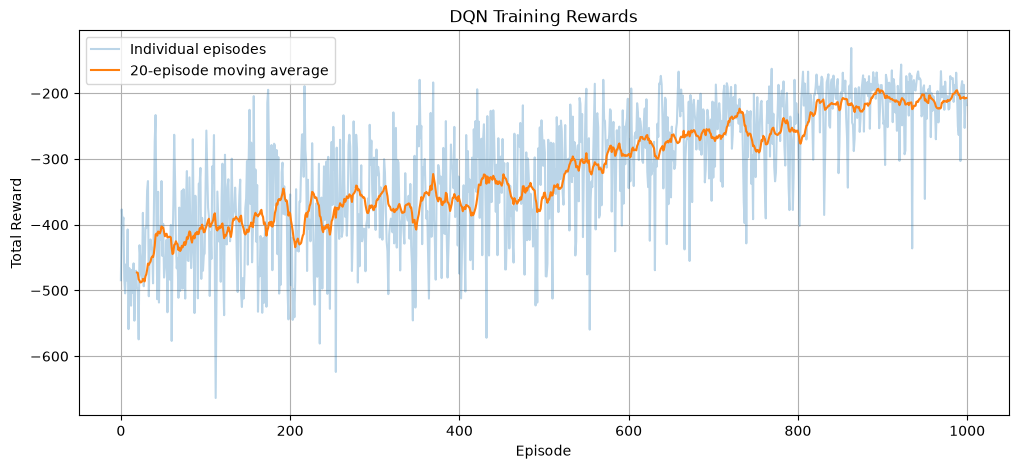

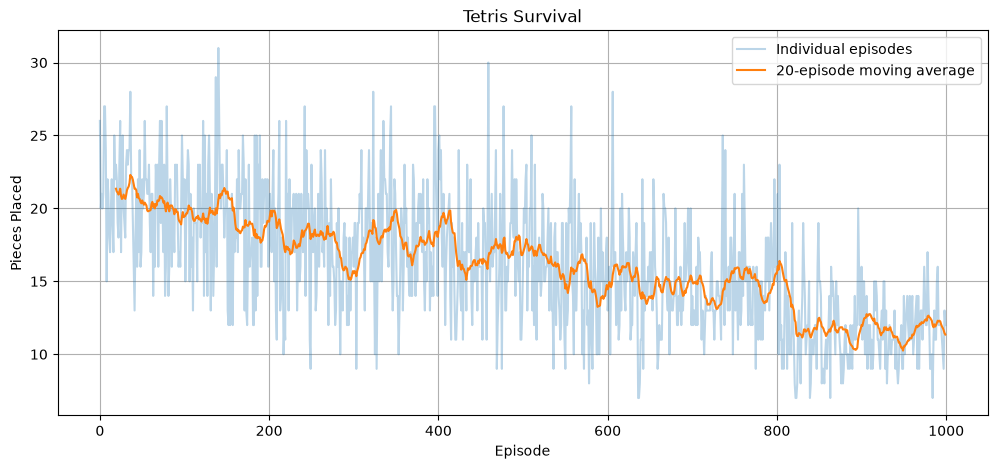

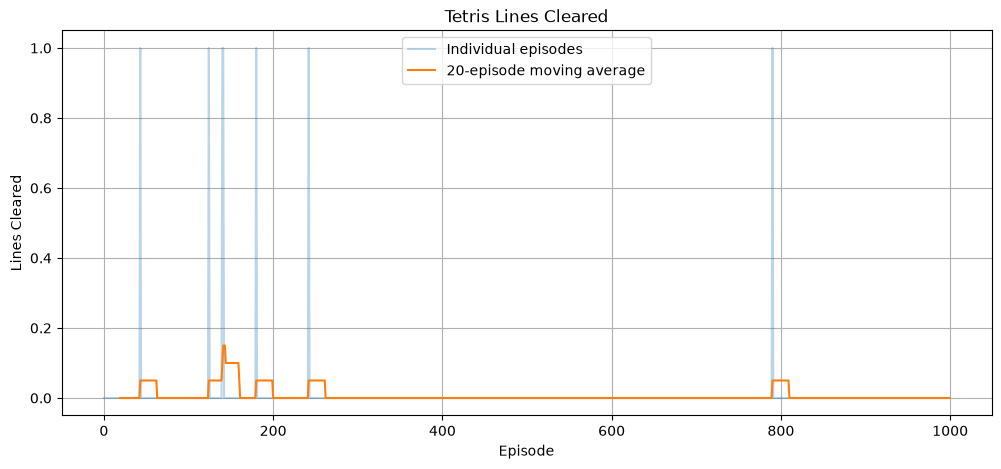

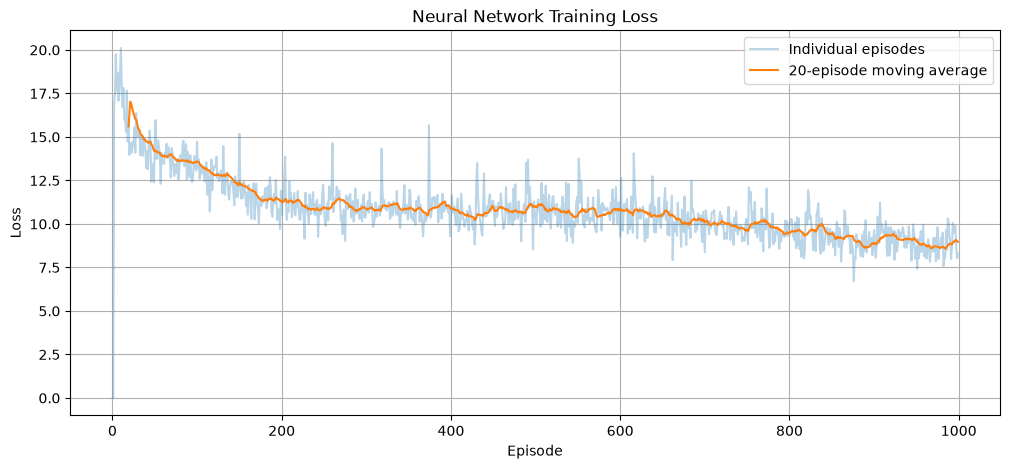

In [82]:
import numpy as np

env = TetrisEnv()
agent = DQNAgent()

episodes = 1000
max_pieces = 2000
train_freq = 2

scores = []
pieces_history = []
lines_history = []
loss_history = []

global_step = 0

for episode in range(episodes):

    state = env.reset()
    total_reward = 0
    losses = []
    done = False

    for step in range(max_pieces):
        valid_actions = env.valid_actions()
        if not np.any(valid_actions):
            break

        action = agent.select_action(state, valid_actions)
        next_state, reward, done = env.step(action)
        truncated = (step == max_pieces - 1)
        next_mask = env.valid_actions()
        
        terminal = done or truncated or not np.any(next_mask)
        if terminal:
            next_mask = np.zeros(40, dtype=bool)

        agent.remember(state, action, reward, next_state, terminal, next_mask)
        global_step += 1

        if global_step % train_freq == 0:
            loss = agent.train_step()

            if loss is not None:
                losses.append(loss)

        state = next_state
        total_reward += reward

        if terminal:
            break

    agent.decay_epsilon()

    scores.append(total_reward)
    pieces_history.append(env.pieces_placed)
    lines_history.append(env.rows_cleared)

    loss_history.append(
        np.mean(losses) if losses else 0
    )

    print(
        f"Episode: {episode + 1}/{episodes} | "
        f"Pieces: {env.pieces_placed} | "
        f"Lines: {env.rows_cleared} | "
        f"Reward: {total_reward:.2f} | "
        f"Epsilon: {agent.epsilon:.3f}"
    )

def plot_training(history, title, ylabel):
    plt.figure(figsize=(12, 5))
    plt.plot(history, alpha=0.3, label="Individual episodes")

    if len(history) >= 20:
        moving_avg = np.convolve(history, np.ones(20) / 20, mode="valid")
        plt.plot(range(19, len(history)), moving_avg, label="20-episode moving average")

    plt.title(title)
    plt.xlabel("Episode")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid()
    plt.show()

plot_training(scores, "DQN Training Rewards", "Total Reward")
plot_training(pieces_history, "Tetris Survival", "Pieces Placed")
plot_training(lines_history, "Tetris Lines Cleared", "Lines Cleared")
plot_training(loss_history,"Neural Network Training Loss", "Loss")

##### 6. Fine Tune the Model

With the select model descibe the steps taken to acheve the best rusults possiable 

In [86]:
torch.save(agent.policy_net.state_dict(), "dqn_tetris.pth")
print("model saved")

model saved


# 7. Present
In a customer faceing Document provide summery of finding and detail approach taken



# 8. Launch the Model System
Define your production run code, This should be self susficent and require only your model pramaters 


In [87]:
import sys
sys.path.insert(0, "src")
from game import Game

game = Game("student")
pieces, rows = game.run_no_visual()

print("Pieces placed:", pieces)
print("Rows cleared:", rows)

IN Play i : 1 y: 0
best_x 0 best_piece <piece.Piece object at 0x7f7449f788f0>
1 0
IN Play i : 1 y: 2
best_x 1 best_piece <piece.Piece object at 0x7f74402cb110>
2 0
IN Play i : 1 y: 3
best_x 3 best_piece <piece.Piece object at 0x7f74402c9130>
3 0
IN Play i : 1 y: 0
best_x 6 best_piece <piece.Piece object at 0x7f74402d7380>
4 0
IN Play i : 1 y: 4
best_x 0 best_piece <piece.Piece object at 0x7f74402c9520>
5 0
list index out of range
OUT of PLAY
list index out of range
OUT of PLAY
IN Play i : 3 y: 4
best_x 5 best_piece <piece.Piece object at 0x7f74402c9130>
6 0
IN Play i : 1 y: 0
best_x 8 best_piece <piece.Piece object at 0x7f74402c9520>
7 0
IN Play i : 1 y: 4
best_x 7 best_piece <piece.Piece object at 0x7f74402b5fa0>
8 0
IN Play i : 1 y: 7
best_x 8 best_piece <piece.Piece object at 0x7f74402b7320>
9 0
IN Play i : 1 y: 6
best_x 4 best_piece <piece.Piece object at 0x7f74402b61e0>
10 0
list index out of range
OUT of PLAY
list index out of range
OUT of PLAY
IN Play i : 3 y: 10
best_x 6 best_p

In [97]:
game = Game("greedy")
pieces, rows = game.run_no_visual()

print("Greedy pieces:", pieces)
print("Greedy rows:", rows)

1 0
2 0
3 0
4 0
5 0
6 0
7 0
8 0
9 1
10 1
11 1
12 1
13 1
14 2
15 3
16 3
17 4
18 4
19 4
20 4
21 5
22 5
23 5
24 6
25 6
26 7
27 7
28 7
29 7
30 7
31 7
32 7
33 9
34 10
35 11
36 11
37 11
38 11
39 11
40 12
41 13
42 13
43 13
44 13
45 13
46 13
47 16
48 17
49 18
50 21
51 22
52 22
53 22
54 22
55 22
56 22
57 22
58 22
59 23
60 23
61 23
62 24
63 25
64 26
65 27
66 27
67 27
68 27
69 27
70 28
71 29
72 29
73 29
74 29
75 30
76 30
77 31
78 31
79 32
80 32
81 32
82 33
83 34
84 34
85 34
86 34
87 35
88 35
89 36
90 37
91 38
92 38
93 38
94 39
95 39
96 39
97 39
98 40
99 40
100 40
101 40
102 41
103 41
104 42
105 42
106 42
107 43
108 43
109 43
110 43
111 44
112 44
113 44
114 45
115 46
116 46
117 46
118 47
119 48
120 48
121 48
122 48
123 49
124 49
125 50
126 50
127 50
128 50
129 50
130 50
131 50
132 50
133 50
134 50
135 50
136 50
137 51
138 51
139 53
140 54
141 54
142 54
143 54
144 54
145 54
146 55
147 55
148 56
149 57
150 57
151 57
152 58
153 58
154 59
155 60
156 60
157 61
158 62
159 62
160 62
161 63
162 63
163 64
